In [6]:
# ------------------------------------------------------------
# 1. IMPORTATION DES BIBLIOTHEQUES
# ------------------------------------------------------------

import os
import re
import sqlite3
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from scipy.stats import t
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score
)

from shapely.geometry import LineString, MultiLineString


warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 2. CHEMINS ET PARAMETRES
# ------------------------------------------------------------

dossier = (
    "/Users/andredenis/Library/CloudStorage/"
    "OneDrive-OneDrive-UniversitédeLausanne(2)/"
    "3eme/Geoinfo2/rendu-Final"
)

# GeoPackage contenant les itineraires
chemin_gpkg = os.path.join(
    dossier,
    "data.gpkg"
)

# Couche contenant les itineraires du Valais
couche_itineraires = "input_itineraires_valais"

# MNT du Valais
chemin_mnt = os.path.join(
    dossier,
    "input_mnt_valais.tiff"
)

# Raster de pente du Valais
chemin_pente = os.path.join(
    dossier,
    "input_pente_valais.tif"
)

# GeoPackage dans lequel seront enregistres les resultats
chemin_sortie = chemin_gpkg

# Distance entre les points d'echantillonnage
pas_echantillonnage = 10  # metres

# Pourcentage utilise pour la validation
taille_test = 0.20

# Graine aleatoire
random_state = 42


# ------------------------------------------------------------
# 3. VERIFICATION DES FICHIERS ET LECTURE
# ------------------------------------------------------------

for chemin in [
    chemin_gpkg,
    chemin_mnt,
    chemin_pente
]:
    if not os.path.exists(chemin):
        raise FileNotFoundError(
            f"Fichier introuvable : {chemin}"
        )

print("Tous les fichiers necessaires sont presents.")

print("\nLecture des itineraires...")
gdf = gpd.read_file(
    chemin_gpkg,
    layer=couche_itineraires,
    engine="pyogrio"
)

print("Nombre d'itineraires :", len(gdf))
print("CRS des itineraires :", gdf.crs)

if "difficulty_fr" not in gdf.columns:
    raise ValueError(
        "La colonne 'difficulty_fr' est absente. "
        "Verifie le nom du champ contenant les cotations."
    )

gdf = gdf[
    gdf.geometry.notna()
    & ~gdf.geometry.is_empty
].copy()

Tous les fichiers necessaires sont presents.

Lecture des itineraires...
Nombre d'itineraires : 2461
CRS des itineraires : EPSG:2056



MNT : EPSG:2056
Pente : EPSG:2056

--- ANALYSE EXPLORATOIRE ---

Statistiques descriptives de base :
               sacid        sactid discipline         source  \
count     580.000000  5.800000e+02       2461           2461   
unique           NaN           NaN          1              2   
top              NaN           NaN   ski_tour  swisstopo_sac   
freq             NaN           NaN       2461           2404   
mean    12755.268966  2.998452e+08        NaN            NaN   
std     15237.770139  7.448591e+08        NaN            NaN   
min      1144.000000  1.000000e+01        NaN            NaN   
25%      3619.750000  1.193000e+03        NaN            NaN   
50%      5657.000000  2.474500e+03        NaN            NaN   
75%      7253.750000  8.794750e+03        NaN            NaN   
max     42604.000000  2.147460e+09        NaN            NaN   

                              name                     name_de  \
count                         2461                        2384 

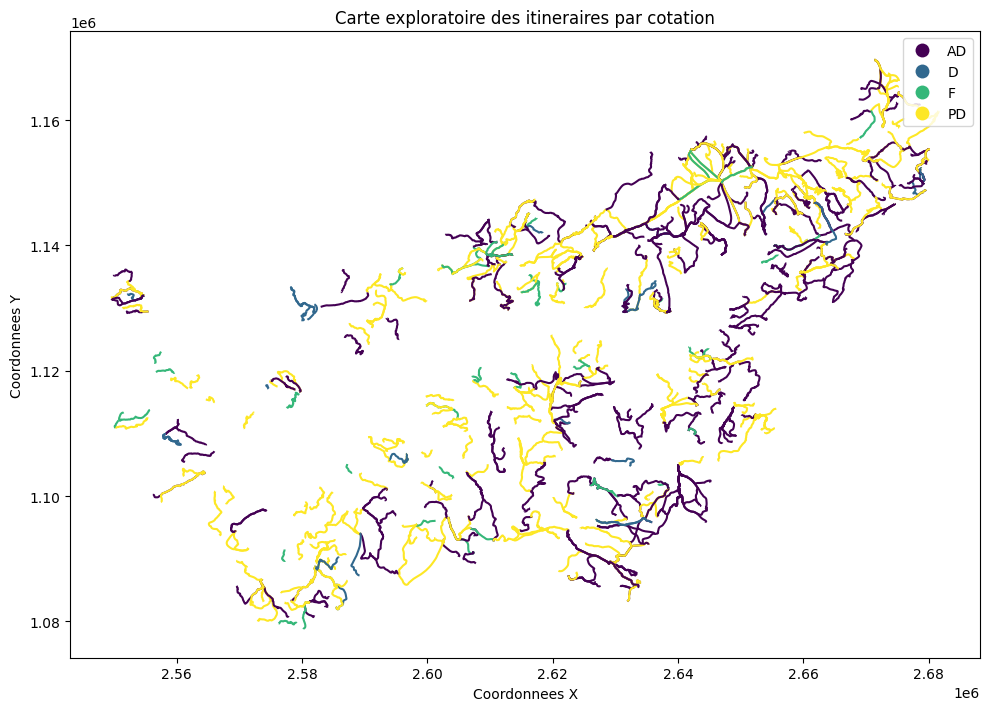

In [8]:
# ------------------------------------------------------------
# 5. OUVERTURE DES RASTERS
# ------------------------------------------------------------

mnt = rasterio.open(chemin_mnt)
pente = rasterio.open(chemin_pente)

print("\nMNT :", mnt.crs)
print("Pente :", pente.crs)

# Mise dans le meme systeme de coordonnees que le MNT
if gdf.crs != mnt.crs:
    gdf = gdf.to_crs(mnt.crs)

if pente.crs != mnt.crs:
    raise ValueError(
        "Le MNT et le raster de pente n'ont pas le meme CRS."
    )


# ------------------------------------------------------------
# 6. FONCTIONS D'ECHANTILLONNAGE
# ------------------------------------------------------------

def obtenir_points_ligne(geom, pas=10):
    """
    Cree des points regulierement espaces le long
    d'une ligne ou d'une MultiLineString.
    """
    if geom is None or geom.is_empty:
        return []

    if isinstance(geom, LineString):
        parties = [geom]
    elif isinstance(geom, MultiLineString):
        parties = list(geom.geoms)
    else:
        return []

    points_par_partie = []

    for ligne in parties:
        longueur = ligne.length
        if longueur <= 0:
            continue

        distances = np.arange(0, longueur, pas)
        if len(distances) == 0 or distances[-1] != longueur:
            distances = np.append(distances, longueur)

        points = [
            ligne.interpolate(float(d))
            for d in distances
        ]
        points_par_partie.append(points)

    return points_par_partie


def extraire_valeurs_raster(src, points):
    """
    Extrait les valeurs d'un raster aux coordonnees
    des points fournis.
    """
    if len(points) == 0:
        return np.array([])

    coordonnees = [(point.x, point.y) for point in points]
    valeurs = []

    for valeur in src.sample(coordonnees, masked=True):
        v = valeur[0]
        if np.ma.is_masked(v):
            valeurs.append(np.nan)
        else:
            v = float(v)
            if src.nodata is not None and np.isclose(v, src.nodata):
                valeurs.append(np.nan)
            else:
                valeurs.append(v)

    return np.array(valeurs, dtype=float)


# ------------------------------------------------------------
# 7. ANALYSE EXPLORATOIRE ET STATISTIQUES DES DONNEES BRUTES
# ------------------------------------------------------------

print("\n--- ANALYSE EXPLORATOIRE ---")

# Aperçu statistique de base des colonnes disponibles
print("\nStatistiques descriptives de base :")
print(gdf.describe(include="all"))


# ------------------------------------------------------------
# 8. NETTOYAGE DES COTATIONS (Ignorer les + et - pour garder uniquement la lettre)
# ------------------------------------------------------------

def nettoyer_cotation(valeur):
    if pd.isna(valeur):
        return np.nan
    
    valeur = str(valeur).strip().upper()
    
    # Suppression des signes + et - (on ne garde que la lettre principale)
    valeur = re.sub(r"[+-]", "", valeur)

    correspondances = {
        "F": "F",
        "PD": "PD",
        "AD": "AD",
        "D": "D"
    }
    
    return correspondances.get(valeur, np.nan)


if "difficulty_fr" in gdf.columns:
    gdf["difficulty_nettoyee"] = gdf["difficulty_fr"].apply(nettoyer_cotation)
    
    # Correspondance numerique pour les modeles
    correspondance = {
        "F": 1,
        "PD": 2,
        "AD": 3,
        "D": 4
    }
    gdf["difficulty_num"] = gdf["difficulty_nettoyee"].map(correspondance)

    print("\nRepartition des cotations nettoyees (sans + ni -) :")
    print(gdf["difficulty_nettoyee"].value_counts(dropna=False))


# Exemple de visualisation cartographique rapide
fig, ax = plt.subplots(figsize=(10, 8))
colonne_carte = "difficulty_nettoyee" if "difficulty_nettoyee" in gdf.columns else None
gdf.plot(ax=ax, column=colonne_carte, legend=True, cmap="viridis")
plt.title("Carte exploratoire des itineraires par cotation")
plt.xlabel("Coordonnees X")
plt.ylabel("Coordonnees Y")
plt.tight_layout()
plt.show()

In [11]:
import numpy as np
import rasterio
from shapely.geometry import LineString, MultiLineString

pas_echantillonnage = 10  # mètres

def obtenir_points_ligne(geom, pas=10):
    if geom is None or geom.is_empty:
        return []

    if isinstance(geom, LineString):
        parties = [geom]
    elif isinstance(geom, MultiLineString):
        parties = list(geom.geoms)
    else:
        return []

    points_par_partie = []
    for ligne in parties:
        longueur = ligne.length
        if longueur <= 0:
            continue

        distances = np.arange(0, longueur, pas)
        if len(distances) == 0 or distances[-1] != longueur:
            distances = np.append(distances, longueur)

        points = [ligne.interpolate(float(d)) for d in distances]
        points_par_partie.append(points)

    return points_par_partie

def extraire_valeurs_raster(src, points):
    if len(points) == 0:
        return np.array([])

    coordonnees = [(point.x, point.y) for point in points]
    valeurs = []

    for valeur in src.sample(coordonnees, masked=True):
        v = valeur[0]
        if np.ma.is_masked(v):
            valeurs.append(np.nan)
        else:
            v = float(v)
            if src.nodata is not None and np.isclose(v, src.nodata):
                valeurs.append(np.nan)
            else:
                valeurs.append(v)

    return np.array(valeurs, dtype=float)

def analyser_itineraire_complet(geom, mnt_src):
    """
    Calcule tout depuis le MNT : 
    - Altitude de départ (premier point)
    - Altitude d'arrivée (dernier point)
    - Longueur et dénivelé positif
    - Pentes (moyenne, max, p95) calculées à partir du MNT
    """
    points_par_partie = obtenir_points_ligne(geom, pas_echantillonnage)
    if len(points_par_partie) == 0:
        return None

    altitudes_toutes = []
    pentes_toutes = []

    denivele_positif = 0
    longueur_couverte = 0
    premiere_altitude = np.nan
    derniere_altitude = np.nan

    for points in points_par_partie:
        altitudes = extraire_valeurs_raster(mnt_src, points)
        masque_alt = np.isfinite(altitudes)
        altitudes_valides = altitudes[masque_alt]

        if len(altitudes_valides) >= 2:
            # Récupération de l'altitude de départ sur le premier point valide de la ligne
            if not np.isfinite(premiere_altitude):
                premiere_altitude = altitudes_valides[0]
            
            # Mise à jour continue pour garder l'altitude du tout dernier point de la ligne
            derniere_altitude = altitudes_valides[-1]

            # Calcul du dénivelé et de la pente à partir du MNT
            differences = np.diff(altitudes_valides)
            denivele_positif += np.sum(differences[differences > 0])
            longueur_couverte += (len(altitudes_valides) - 1) * pas_echantillonnage

            pentes_rad = np.arctan(np.abs(differences) / pas_echantillonnage)
            pentes_deg = np.degrees(pentes_rad)
            pentes_toutes.extend(pentes_deg)

        if len(altitudes_valides) > 0:
            altitudes_toutes.extend(altitudes_valides)

    altitudes_toutes = np.array(altitudes_toutes, dtype=float)
    pentes_toutes = np.array(pentes_toutes, dtype=float)

    if len(altitudes_toutes) < 2 or len(pentes_toutes) == 0:
        return None

    return {
        "altitude_depart": premiere_altitude,
        "altitude_arrivee": derniere_altitude,
        "longueur_valais_km": longueur_couverte / 1000,
        "denivele_positif": denivele_positif,
        "pente_moyenne": np.mean(pentes_toutes),
        "pente_max": np.max(pentes_toutes),
        "pente_p95": np.percentile(pentes_toutes, 95)
    }

In [13]:
print("\nExtraction des variables topographiques pour tous les itinéraires...")

resultats = []
for i, geom in enumerate(gdf.geometry):
    resultat = analyser_itineraire_complet(geom, mnt)  # ou analyser_itineraire selon le nom de ta fonction
    if resultat is None:
        resultat = {
            "altitude_depart": np.nan,
            "altitude_arrivee": np.nan,
            "longueur_valais_km": np.nan,
            "denivele_positif": np.nan,
            "pente_moyenne": np.nan,
            "pente_max": np.nan,
            "pente_p95": np.nan
        }
    resultats.append(resultat)

# Ajout des colonnes calculées dans le GeoDataFrame principal
variables = pd.DataFrame(resultats)
for colonne in variables.columns:
    gdf[colonne] = variables[colonne].values

print("Extraction terminée ! Les colonnes sont maintenant dans gdf.")


Extraction des variables topographiques pour tous les itinéraires...
Extraction terminée ! Les colonnes sont maintenant dans gdf.


In [14]:
# ------------------------------------------------------------
# 19. PREDICTION SUR TOUS LES ITINERAIRES (Y COMPRIS CEUX SANS COTATION)
# ------------------------------------------------------------

# On entraîne le modèle final sur l'intégralité des données cotées
modele_final = LinearRegression()
modele_final.fit(X, y)

# Sélection de tous les itinéraires qui ont les variables topographiques
donnees_completes = gdf.dropna(subset=variables_explicatives).copy()
X_complet = donnees_completes[variables_explicatives]

# Prédictions sur l'ensemble
predictions_finales = modele_final.predict(X_complet)
predictions_finales_limitees = np.clip(predictions_finales, 1, 4)
classes_finales = np.rint(predictions_finales_limitees).astype(int)

# Création d'une couche globale pour l'export
resultats_predictions = gdf.copy()
resultats_predictions["prediction_brute"] = np.nan
resultats_predictions["prediction_classe_num"] = np.nan
resultats_predictions["cotation_predite"] = None

resultats_predictions.loc[donnees_completes.index, "prediction_brute"] = predictions_finales
resultats_predictions.loc[donnees_completes.index, "prediction_classe_num"] = classes_finales

correspondance_inverse = {1: "F", 2: "PD", 3: "AD", 4: "D"}
resultats_predictions.loc[donnees_completes.index, "cotation_predite"] = [
    correspondance_inverse[c] for c in classes_finales
]

# ------------------------------------------------------------
# 20. EXPORT DES RESULTATS DANS LE GEOPACKAGE
# ------------------------------------------------------------

chemin_sortie = chemin_gpkg

print("\nExport des résultats dans le GeoPackage...")
resultats_predictions.to_file(
    chemin_sortie,
    layer="results_predictions",
    driver="GPKG",
    engine="pyogrio",
    mode="a",
    index=False
)
print("Couche 'results_predictions' exportée avec succès !")


Export des résultats dans le GeoPackage...
Couche 'results_predictions' exportée avec succès !


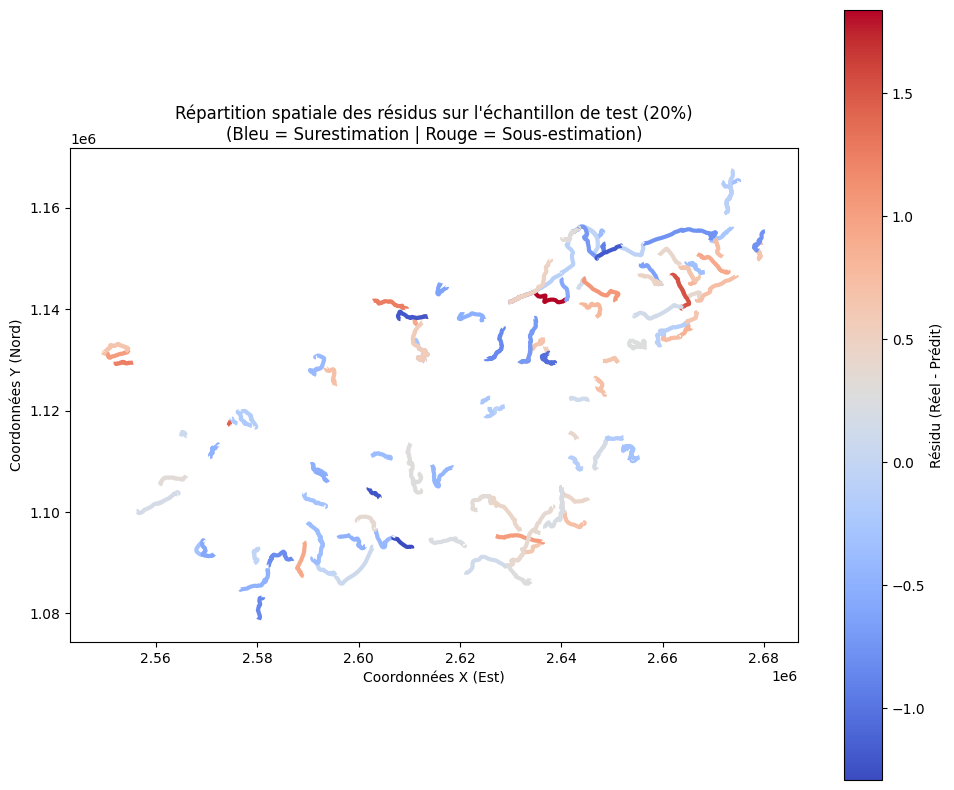

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

# On trace les itinéraires de test avec des lignes plus épaisses
resultats_test.plot(
    ax=ax,
    column="residu",
    cmap="coolwarm",
    legend=True,
    linewidth=3,          # <--- Augmente l'épaisseur ici (essaie 3 ou 4)
    legend_kwds={"label": "Résidu (Réel - Prédit)"}
)

plt.title("Répartition spatiale des résidus sur l'échantillon de test (20%)\n(Bleu = Surestimation | Rouge = Sous-estimation)")
plt.xlabel("Coordonnées X (Est)")
plt.ylabel("Coordonnées Y (Nord)")
plt.tight_layout()
plt.show()

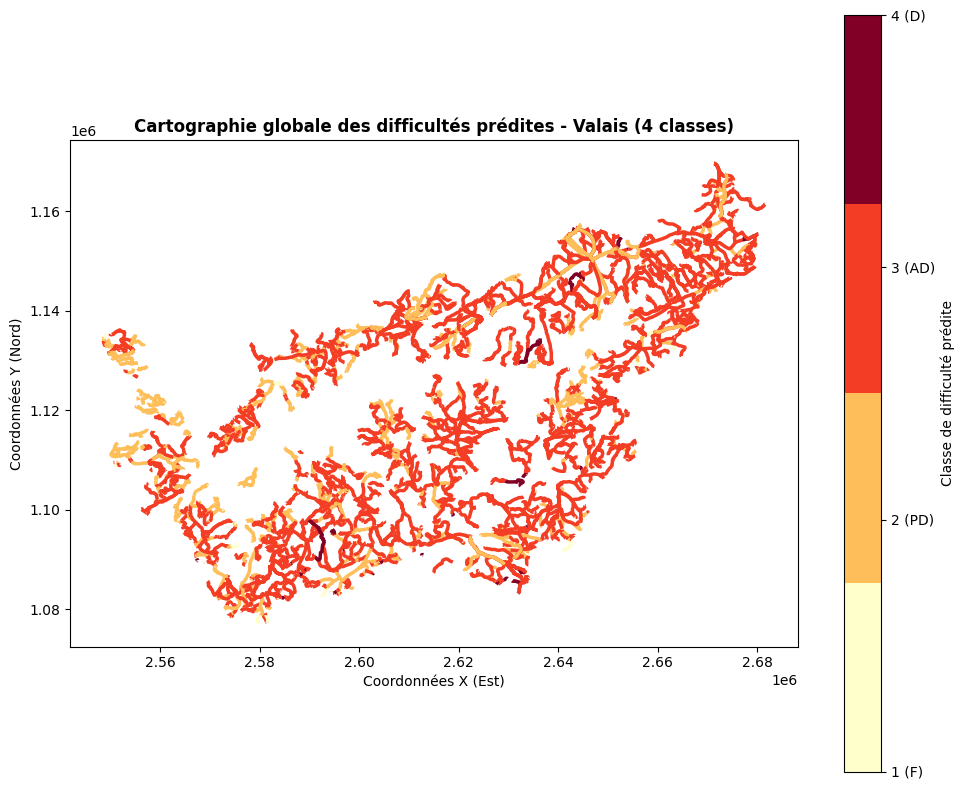

In [24]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

fig, ax = plt.subplots(figsize=(10, 8))

# Définition d'une palette à 4 couleurs discrètes
cmap = plt.get_cmap("YlOrRd", 4)

# Tracé de la carte
carte = gdf.plot(
    ax=ax,
    column="prediction_classe_num",
    cmap=cmap,
    linewidth=2.5,
    legend=True,
    legend_kwds={
        "label": "Classe de difficulté prédite",
        "ticks": [1, 2, 3, 4],
        "format": "%d"
    }
)

# Personnalisation de la légende pour afficher F, PD, AD, D
cbar = ax.get_figure().get_axes()[1] # Récupère la colorbar
cbar.set_yticklabels(['1 (F)', '2 (PD)', '3 (AD)', '4 (D)'])

plt.title("Cartographie globale des difficultés prédites - Valais (4 classes)", fontsize=12, fontweight='bold')
plt.xlabel("Coordonnées X (Est)")
plt.ylabel("Coordonnées Y (Nord)")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import r2_score

# R² sur l'échantillon de test (ou sur l'ensemble des données si tu préfères)
r2 = r2_score(y_test, predictions_test)
pourcentage_explication = r2 * 100

print(f"Le modèle explique {pourcentage_explication:.2f}% de la variance de la cotation.")

Le modèle explique 12.93% de la variance de la cotation.


In [27]:
import pandas as pd

# Sélection des variables explicatives + la colonne cible
colonnes_analyse = variables_explicatives + ["difficulty_num"]

# Calcul de la matrice de Pearson
matrice_pearson = donnees_modele[colonnes_analyse].corr(method="pearson")

print("=== MATRICE DE CORRÉLATION DE PEARSON ===")
print(matrice_pearson.round(2).to_string())

=== MATRICE DE CORRÉLATION DE PEARSON ===
                    altitude_depart  altitude_arrivee  longueur_valais_km  denivele_positif  pente_moyenne  pente_max  pente_p95  difficulty_num
altitude_depart                1.00              0.41               -0.34             -0.69          -0.36      -0.20      -0.30            0.02
altitude_arrivee               0.41              1.00                0.08              0.13          -0.22       0.08      -0.11            0.27
longueur_valais_km            -0.34              0.08                1.00              0.77          -0.17       0.41       0.06            0.07
denivele_positif              -0.69              0.13                0.77              1.00           0.23       0.47       0.34            0.20
pente_moyenne                 -0.36             -0.22               -0.17              0.23           1.00       0.31       0.77            0.19
pente_max                     -0.20              0.08                0.41              0

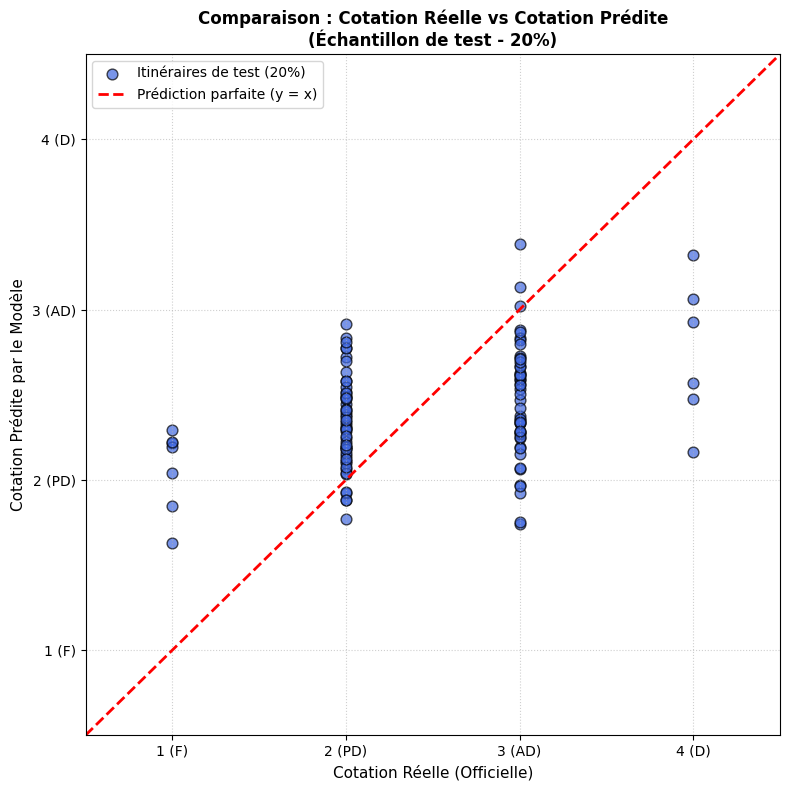

In [28]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 8))

# Nuage de points : Réel vs Prédit sur l'échantillon de test
ax.scatter(
    y_test, 
    predictions_test, 
    alpha=0.7, 
    color='royalblue', 
    edgecolors='k', 
    s=60, 
    label='Itinéraires de test (20%)'
)

# Ligne idéale de référence (y = x) représentant une prédiction parfaite
limites = [0.5, 4.5]
ax.plot(limites, limites, color='red', linestyle='--', linewidth=2, label='Prédiction parfaite (y = x)')

# Configuration des axes avec les libellés de cotation (1=F, 2=PD, 3=AD, 4=D)
niveaux = [1, 2, 3, 4]
labels_cotations = ['1 (F)', '2 (PD)', '3 (AD)', '4 (D)']

ax.set_xticks(niveaux)
ax.set_xticklabels(labels_cotations)
ax.set_yticks(niveaux)
ax.set_yticklabels(labels_cotations)

# Limites des axes
ax.set_xlim(0.5, 4.5)
ax.set_ylim(0.5, 4.5)

# Titre et légendes
ax.set_title("Comparaison : Cotation Réelle vs Cotation Prédite\n(Échantillon de test - 20%)", fontsize=12, fontweight='bold')
ax.set_xlabel("Cotation Réelle (Officielle)", fontsize=11)
ax.set_ylabel("Cotation Prédite par le Modèle", fontsize=11)

ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [29]:
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score, classification_report
)
import numpy as np

# ------------------------------------------------------------
# 1. CALCUL DES MÉTRIQUES DE RÉGRESSION
# ------------------------------------------------------------
r2 = r2_score(y_test, predictions_test)
mae = mean_absolute_error(y_test, predictions_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions_test))

print("=== MÉTRIQUES DE RÉGRESSION ===")
print(f"R² (Variance expliquée) : {r2:.3f} ({r2*100:.1f}%)")
print(f"MAE (Erreur absolue moyenne) : {mae:.3f}")
print(f"RMSE (Erreur quadratique moyenne) : {rmse:.3f}\n")

# ------------------------------------------------------------
# 2. CALCUL DES MÉTRIQUES DE CLASSIFICATION (sur les classes 1 à 4)
# ------------------------------------------------------------
# Conversion des valeurs réelles en classes entières (si ce n'est pas déjà fait)
y_test_classes = y_test.astype(int)
predictions_classes = np.rint(np.clip(predictions_test, 1, 4)).astype(int)

exactitude = accuracy_score(y_test_classes, predictions_classes)
# average='weighted' permet de calculer une moyenne pondérée pour les 4 classes
precision = precision_score(y_test_classes, predictions_classes, average='weighted', zero_division=0)
sensibilite = recall_score(y_test_classes, predictions_classes, average='weighted', zero_division=0)
f1 = f1_score(y_test_classes, predictions_classes, average='weighted', zero_division=0)

print("=== MÉTRIQUES DE CLASSIFICATION (Classes 1 à 4) ===")
print(f"Exactitude (Accuracy) : {exactitude:.3f} ({exactitude*100:.1f}%)")
print(f"Précision (Precision) : {precision:.3f}")
print(f"Sensibilité (Recall) : {sensibilite:.3f}")
print(f"F1-Score : {f1:.3f}\n")

# Optionnel : Rapport détaillé classe par classe (F, PD, AD, D)
print("=== RAPPORT DÉTAILLÉ PAR CLASSE ===")
print(classification_report(y_test_classes, predictions_classes, target_names=['F', 'PD', 'AD', 'D'], zero_division=0))

=== MÉTRIQUES DE RÉGRESSION ===
R² (Variance expliquée) : 0.129 (12.9%)
MAE (Erreur absolue moyenne) : 0.533
RMSE (Erreur quadratique moyenne) : 0.646

=== MÉTRIQUES DE CLASSIFICATION (Classes 1 à 4) ===
Exactitude (Accuracy) : 0.558 (55.8%)
Précision (Precision) : 0.498
Sensibilité (Recall) : 0.558
F1-Score : 0.519

=== RAPPORT DÉTAILLÉ PAR CLASSE ===
              precision    recall  f1-score   support

           F       0.00      0.00      0.00         7
          PD       0.54      0.75      0.63        52
          AD       0.59      0.50      0.54        48
           D       0.00      0.00      0.00         6

    accuracy                           0.56       113
   macro avg       0.28      0.31      0.29       113
weighted avg       0.50      0.56      0.52       113

